# Statistical testing of detectors (Friedman & Nemenyi tests)

In [1]:
# Import required libraries
import sys
import os
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scikit_posthocs as sp
from scipy import stats
import seaborn as sns

# Add parent directory to path
sys.path.append(os.path.abspath(os.path.join('..')))

# Import project custom modules
from src.detector.statistical_tests import evaluate_detectors_statistically

# Configure plot styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## Input data

In [2]:
data_dir = "../data"
processed_dir = Path(data_dir) / "processed"
detectors_results_path = processed_dir / "multi_series_detector_comparison_results.csv"

## 1. Data preparation

In [3]:
df_raw = pd.read_csv(detectors_results_path)

print(f"Original shape: {df_raw.shape}")
print("Unique datasets:", df_raw["dataset"].unique())
print("Unique methods:", df_raw["method"].unique())
print("Drift types present:", df_raw["drift_type"].unique())

Original shape: (679, 13)
Unique datasets: <ArrowStringArray>
['Alibaba', 'UCI_Electricity', 'TCPD']
Length: 3, dtype: str
Unique methods: <ArrowStringArray>
[                'ks',                'psi',        'wasserstein',
              'adwin',       'page_hinkley',              'kswin',
 'residual_conformal']
Length: 7, dtype: str
Drift types present: <ArrowStringArray>
['none', 'abrupt', 'gradual', 'seasonal_amplitude',
 'real_consensus_annotation']
Length: 5, dtype: str


### Level 1. FAR per 1000

In [4]:
# Filter out level 1 drift scenarios to evaluate detection performance (FAR per 1000) on actual drift instances
df_drift = df_raw[(df_raw["level"] == 1)].copy()

In [5]:
# Target metric for statistical comparison.
benchmark_id_cols = ["dataset", "series_id", "level"]

df_pivot_far_per_1000 = (
    df_drift.groupby(benchmark_id_cols + ["method"])["far_per_1000"]
    .mean()
    .unstack(level="method")
)

In [6]:
# Drop any benchmark rows that contain missing values for a fair Friedman test (complete block design)
df_pivot_far_per_1000 = df_pivot_far_per_1000.dropna()

print(f"\nPivoted Data Shape for Statistical Tests: {df_pivot_far_per_1000.shape}")
df_pivot_far_per_1000


Pivoted Data Shape for Statistical Tests: (10, 7)


method                                          adwin     ks  kswin  \
dataset         series_id                level                        
Alibaba         alibaba_mem_util_percent 1       5.80  22.29   8.47   
                alibaba_net_in           1       2.67  35.67   9.81   
TCPD            iceland_tourism          1       0.00   0.00   5.03   
                jfk_passengers           1       0.00   0.00   0.00   
                us_population            1       0.00   3.68   4.90   
UCI_Electricity MT_209                   1       0.34   2.97   2.17   
                MT_241                   1       0.11   3.08   2.63   
                MT_242                   1       0.11   4.34   2.74   
                MT_265                   1       0.00   1.03   2.17   
                MT_291                   1       0.46   2.28   3.20   

method                                          page_hinkley    psi  \
dataset         series_id                level                        
Alibaba         alibaba_mem_util_percent 1             10.70  36.56   
                alibaba_net_in           1              0.89  36.56   
TCPD            iceland_tourism          1             30.15   0.00   
                jfk_passengers           1             32.05  19.23   
                us_population            1             33.09  30.64   
UCI_Electricity MT_209                   1             33.33  34.59   
                MT_241                   1             33.33  36.99   
                MT_242                   1             33.33  36.07   
                MT_265                   1             33.33  35.84   
                MT_291                   1             33.33  36.30   

method                                          residual_conformal  \
dataset         series_id                level                       
Alibaba         alibaba_mem_util_percent 1               13.374944   
                alibaba_net_in           1               16.495765   
TCPD            iceland_tourism          1                0.000000   
                jfk_passengers           1                4.273504   
                us_population            1                8.578431   
UCI_Electricity MT_209                   1                5.479452   
                MT_241                   1                6.050228   
                MT_242                   1                6.392694   
                MT_265                   1                4.680365   
                MT_291                   1                5.707763   

method                                          wasserstein  
dataset         series_id                level               
Alibaba         alibaba_mem_util_percent 1            32.10  
                alibaba_net_in           1             0.00  
TCPD            iceland_tourism          1             0.00  
                jfk_passengers           1            23.50  
                us_population            1            30.64  
UCI_Electricity MT_209                   1            39.16  
                MT_241                   1            39.16  
                MT_242                   1            39.16  
                MT_265                   1            39.16  
                MT_291                   1            39.16

### Level 2. Synthetic drift

In [7]:
# Filter out 'none' drift scenarios to evaluate detection performance (Delay / F1) on actual drift instances
df_drift_synthetic_data = df_raw[(df_raw["drift_type"] != "none") & (df_raw["level"] == 2)].copy()

In [8]:
# Target metric for statistical comparison.
benchmark_id_cols = ["dataset", "level", "drift_type", "magnitude"]

df_pivot_f1_synthetic_data = (
    df_drift_synthetic_data.groupby(benchmark_id_cols + ["method"])["f1_score"]
    .mean()
    .unstack(level="method")
)

df_pivot_detection_delay_synthetic_data = (
    df_drift_synthetic_data.groupby(benchmark_id_cols + ["method"])["detection_delay"]
    .mean()
    .unstack(level="method")
)

In [9]:
# Drop any benchmark rows that contain missing values for a fair Friedman test (complete block design)
df_pivot_f1_synthetic_data = df_pivot_f1_synthetic_data.dropna()

print(f"\nPivoted Data Shape for Statistical Tests: {df_pivot_f1_synthetic_data.shape}")
df_pivot_f1_synthetic_data.head(50)


Pivoted Data Shape for Statistical Tests: (24, 7)


method                                              adwin     ks  kswin  \
dataset         level drift_type         magnitude                        
Alibaba         2     abrupt             0.5        0.110  0.070  0.085   
                                         1.0        0.110  0.070  0.085   
                                         2.0        0.110  0.070  0.085   
                                         3.0        0.110  0.025  0.000   
                      gradual            0.5        0.000  0.070  0.000   
                                         1.0        0.000  0.070  0.085   
                                         2.0        0.000  0.070  0.085   
                                         3.0        0.000  0.070  0.000   
                      seasonal_amplitude 0.5        0.000  0.070  0.000   
                                         1.0        0.000  0.070  0.085   
                                         2.0        0.000  0.070  0.000   
                                         3.0        0.000  0.070  0.085   
UCI_Electricity 2     abrupt             0.5        0.000  0.008  0.012   
                                         1.0        0.000  0.008  0.000   
                                         2.0        0.000  0.008  0.012   
                                         3.0        0.000  0.008  0.012   
                      gradual            0.5        0.000  0.008  0.028   
                                         1.0        0.000  0.008  0.014   
                                         2.0        0.000  0.008  0.016   
                                         3.0        0.000  0.008  0.030   
                      seasonal_amplitude 0.5        0.000  0.008  0.014   
                                         1.0        0.000  0.008  0.014   
                                         2.0        0.000  0.008  0.042   
                                         3.0        0.138  0.008  0.028   

method                                              page_hinkley    psi  \
dataset         level drift_type         magnitude                        
Alibaba         2     abrupt             0.5               0.055  0.050   
                                         1.0               0.055  0.050   
                                         2.0               0.055  0.050   
                                         3.0               0.200  0.050   
                      gradual            0.5               0.000  0.050   
                                         1.0               0.000  0.050   
                                         2.0               0.000  0.050   
                                         3.0               0.000  0.050   
                      seasonal_amplitude 0.5               0.055  0.050   
                                         1.0               0.055  0.050   
                                         2.0               0.055  0.050   
                                         3.0               0.055  0.050   
UCI_Electricity 2     abrupt             0.5               0.010  0.010   
                                         1.0               0.010  0.008   
                                         2.0               0.010  0.008   
                                         3.0               0.010  0.010   
                      gradual            0.5               0.010  0.010   
                                         1.0               0.010  0.010   
                                         2.0               0.010  0.010   
                                         3.0               0.010  0.010   
                      seasonal_amplitude 0.5               0.010  0.010   
                                         1.0               0.010  0.010   
                                         2.0               0.010  0.010   
                                         3.0               0.010  0.010   

method                                              residual_conformal  \
dataset         level dr

In [10]:
# Drop any benchmark rows that contain missing values for a fair Friedman test (complete block design)
df_pivot_detection_delay_synthetic_data = df_pivot_detection_delay_synthetic_data.dropna()

print(f"\nPivoted Data Shape for Statistical Tests: {df_pivot_detection_delay_synthetic_data.shape}")
df_pivot_detection_delay_synthetic_data


Pivoted Data Shape for Statistical Tests: (23, 7)


method                                               adwin    ks  kswin  \
dataset         level drift_type         magnitude                        
Alibaba         2     abrupt             0.5         126.0   4.0   60.0   
                                         1.0         126.0   4.0   60.5   
                                         2.0         126.0   4.0   58.5   
                                         3.0         126.0  29.0  105.5   
                      gradual            0.5         142.0   4.0   71.0   
                                         1.0         142.0   4.0   56.0   
                                         2.0         142.0   4.0   66.0   
                                         3.0         126.0   4.0   79.0   
                      seasonal_amplitude 0.5         142.0   4.0   72.0   
                                         1.0         142.0   4.0   56.0   
                                         2.0         142.0   4.0   74.5   
                                         3.0         142.0   4.0   63.5   
UCI_Electricity 2     abrupt             0.5         732.6  85.0   69.8   
                                         1.0         271.8  90.0   68.0   
                                         2.0         111.8  75.0   61.8   
                      gradual            0.5         777.4  95.0   59.8   
                                         1.0         803.0  95.0   60.6   
                                         2.0         835.0  95.0   58.2   
                                         3.0         886.2  95.0   61.4   
                      seasonal_amplitude 0.5        1468.6  70.0   68.8   
                                         1.0        2153.4  65.0   71.8   
                                         2.0        1545.4  50.0   79.2   
                                         3.0        1315.0  45.0  224.8   

method                                              page_hinkley   psi  \
dataset         level drift_type         magnitude                       
Alibaba         2     abrupt             0.5                47.0   4.0   
                                         1.0                37.5   4.0   
                                         2.0                28.0   4.0   
                                         3.0                22.5   4.0   
                      gradual            0.5                58.5   4.0   
                                         1.0                58.0   4.0   
                                         2.0                57.5   4.0   
                                         3.0                57.0   4.0   
                      seasonal_amplitude 0.5                34.5   4.0   
                                         1.0                34.5   4.0   
                                         2.0                34.5   4.0   
                                         3.0                35.0   4.0   
UCI_Electricity 2     abrupt             0.5                23.6  20.0   
                                         1.0                23.6  25.0   
                                         2.0                23.6  25.0   
                      gradual            0.5                23.6  20.0   
                                         1.0                23.6  20.0   
                                         2.0                23.6  20.0   
                                         3.0                23.6  20.0   
                      seasonal_amplitude 0.5                23.6  20.0   
                                         1.0                23.6  20.0   
                                         2.0                23.6  20.0   
                                         3.0                23.6  20.0   

method                                              residual_conformal  \
dataset         level drift_type         magnitude                       
Alibaba         2     abrupt             0.5                      22.5   
                                         1.0       

### Level 3. Real data drift

In [11]:
# Filter out 'none' drift scenarios to evaluate detection performance (Delay / F1) on actual drift instances
df_drift_real_data = df_raw[(df_raw["drift_type"] != "none") & (df_raw["level"] == 3)].copy()

In [12]:
# Target metric for statistical comparison.
benchmark_id_cols = ["dataset", "series_id", "level", "drift_type"]

df_pivot_f1_real_data = (
    df_drift_real_data.groupby(benchmark_id_cols + ["method"])["f1_score"]
    .mean()
    .unstack(level="method")
)

df_pivot_detection_delay_real_data = (
    df_drift_real_data.groupby(benchmark_id_cols + ["method"])["detection_delay"]
    .mean()
    .unstack(level="method")
)

In [13]:
# Drop any benchmark rows that contain missing values for a fair Friedman test (complete block design)
df_pivot_f1_real_data = df_pivot_f1_real_data.dropna()

print(f"\nPivoted Data Shape for Statistical Tests: {df_pivot_f1_real_data.shape}")
df_pivot_f1_real_data


Pivoted Data Shape for Statistical Tests: (3, 7)


method                                                   adwin    ks  kswin  \
dataset series_id       level drift_type                                      
TCPD    iceland_tourism 3     real_consensus_annotation   0.67  0.00   0.00   
        jfk_passengers  3     real_consensus_annotation   0.00  0.22   0.00   
        us_population   3     real_consensus_annotation   0.08  0.08   0.22   

method                                                   page_hinkley   psi  \
dataset series_id       level drift_type                                      
TCPD    iceland_tourism 3     real_consensus_annotation          0.29  0.00   
        jfk_passengers  3     real_consensus_annotation          0.12  0.17   
        us_population   3     real_consensus_annotation          0.07  0.08   

method                                                   residual_conformal  \
dataset series_id       level drift_type                                      
TCPD    iceland_tourism 3     real_consensus_annotation            0.666667   
        jfk_passengers  3     real_consensus_annotation            1.000000   
        us_population   3     real_consensus_annotation            0.400000   

method                                                   wasserstein  
dataset series_id       level drift_type                              
TCPD    iceland_tourism 3     real_consensus_annotation         0.00  
        jfk_passengers  3     real_consensus_annotation         0.17  
        us_population   3     real_consensus_annotation         0.08

In [14]:
# Drop any benchmark rows that contain missing values for a fair Friedman test (complete block design)
df_pivot_detection_delay_real_data = df_pivot_detection_delay_real_data.dropna()

print(f"\nPivoted Data Shape for Statistical Tests: {df_pivot_detection_delay_real_data.shape}")
df_pivot_detection_delay_real_data


Pivoted Data Shape for Statistical Tests: (1, 7)


,,,method,adwin,ks,kswin,page_hinkley,psi,residual_conformal,wasserstein
dataset,series_id,level,drift_type,,,,,,,
TCPD,us_population,3,real_consensus_annotation,17.0,13.0,37.0,17.0,13.0,0.0,13.0


## 2. Statistical testing (Friedman & Nemenyi)

### Level 1. FAR per 1000


=== Statistical Analysis for Metric: FAR per 1000 ===
Friedreg/Chi-square Statistic: 34.2393
p-value: 6.0483e-06
Conclusion: Null hypothesis rejected. Statistically significant differences exist among the detectors.

--- Nemenyi Post-hoc Test p-value Matrix ---
                       adwin        ks     kswin  page_hinkley       psi  \
adwin               1.000000  0.645473  0.774849      0.003668  0.000220   
ks                  0.645473  1.000000  0.999993      0.370538  0.087853   
kswin               0.774849  0.999993  1.000000      0.255021  0.049754   
page_hinkley        0.003668  0.370538  0.255021      1.000000  0.994057   
psi                 0.000220  0.087853  0.049754      0.994057  1.000000   
residual_conformal  0.129608  0.967552  0.916230      0.916230  0.540215   
wasserstein         0.000350  0.114268  0.066581      0.997636  1.000000   

                    residual_conformal  wasserstein  
adwin                         0.129608     0.000350  
ks                  

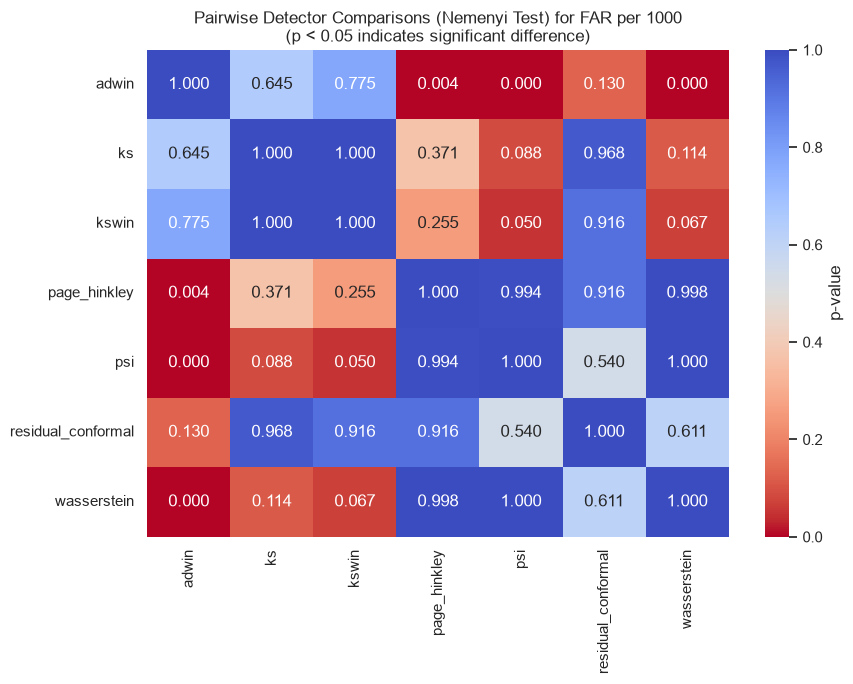

In [15]:
far_per_1000_results_matrix = evaluate_detectors_statistically(df_pivot_far_per_1000, metric_name="FAR per 1000")

### Level 2. Synthetic drift


=== Statistical Analysis for Metric: F1-Score ===
Friedreg/Chi-square Statistic: 35.2208
p-value: 3.9050e-06
Conclusion: Null hypothesis rejected. Statistically significant differences exist among the detectors.

--- Nemenyi Post-hoc Test p-value Matrix ---
                       adwin        ks     kswin  page_hinkley       psi  \
adwin               1.000000  0.169424  0.000132      0.411687  0.680078   
ks                  0.169424  1.000000  0.390550      0.999223  0.977160   
kswin               0.000132  0.390550  1.000000      0.157101  0.056340   
page_hinkley        0.411687  0.999223  0.157101      1.000000  0.999680   
psi                 0.680078  0.977160  0.056340      0.999680  1.000000   
residual_conformal  0.000026  0.210493  0.999890      0.067847  0.020422   
wasserstein         0.225565  1.000000  0.311081      0.999890  0.990436   

                    residual_conformal  wasserstein  
adwin                         0.000026     0.225565  
ks                      

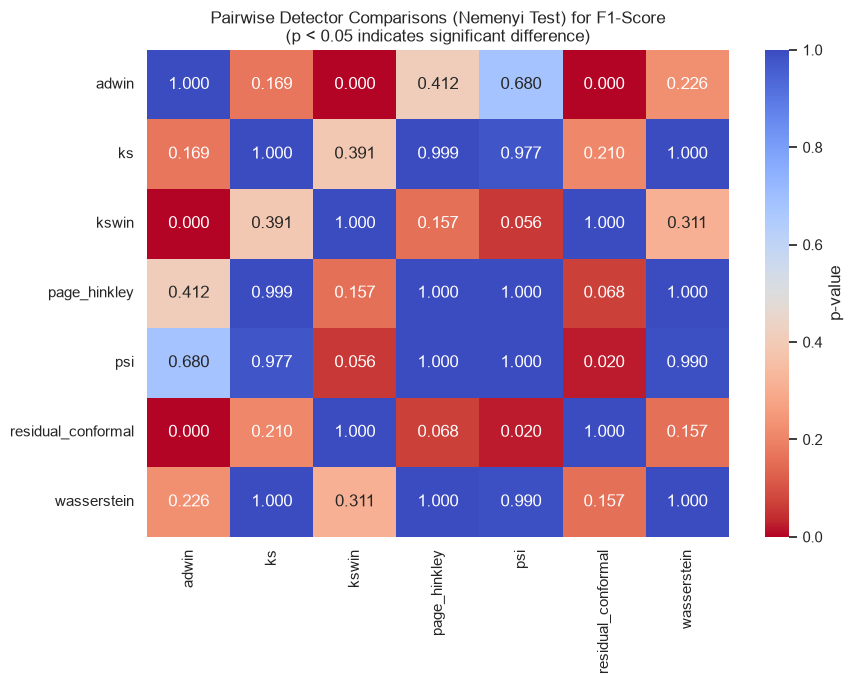

In [16]:
f1_results_matrix_synthetic_data = evaluate_detectors_statistically(df_pivot_f1_synthetic_data, metric_name="F1-Score")


=== Statistical Analysis for Metric: Detection Delay ===
Friedreg/Chi-square Statistic: 93.3360
p-value: 6.1372e-18
Conclusion: Null hypothesis rejected. Statistically significant differences exist among the detectors.

--- Nemenyi Post-hoc Test p-value Matrix ---
                           adwin        ks         kswin  page_hinkley  \
adwin               1.000000e+00  0.000003  3.040746e-01      0.000185   
ks                  2.554052e-06  1.000000  3.130397e-02      0.979155   
kswin               3.040746e-01  0.031304  1.000000e+00      0.267629   
page_hinkley        1.852460e-04  0.979155  2.676288e-01      1.000000   
psi                 2.590150e-13  0.188813  6.750261e-07      0.018181   
residual_conformal  4.336609e-11  0.588636  2.598826e-05      0.127801   
wasserstein         5.728847e-09  0.948715  7.205361e-04      0.495731   

                             psi  residual_conformal   wasserstein  
adwin               2.590150e-13        4.336609e-11  5.728847e-09  
ks 

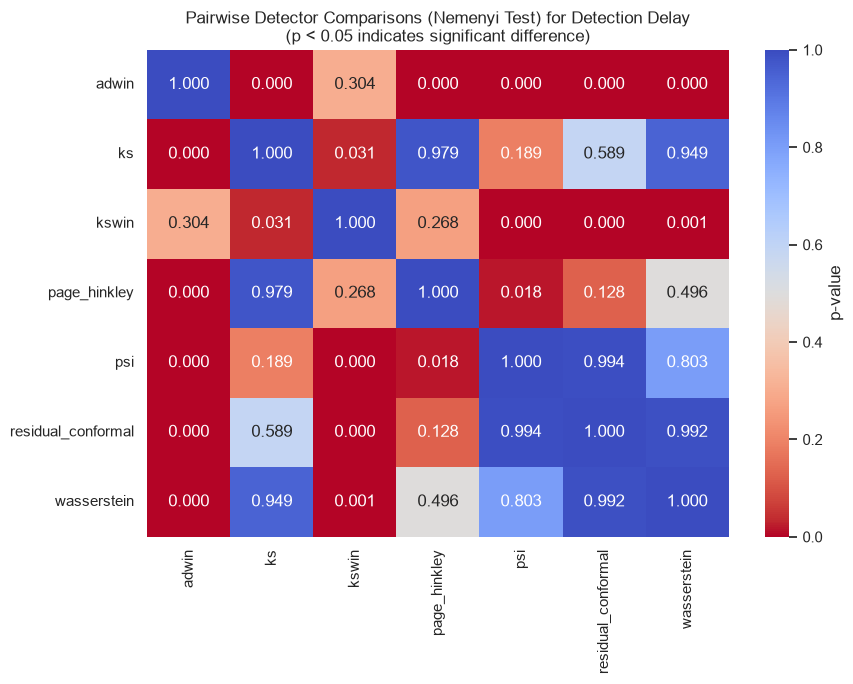

In [17]:
detection_delay_results_matrix_synthetic_data = evaluate_detectors_statistically(df_pivot_detection_delay_synthetic_data, metric_name="Detection Delay")

### Level 3. Real data drift

In [18]:
f1_results_matrix_real_data = evaluate_detectors_statistically(df_pivot_f1_real_data, metric_name="F1-Score")


=== Statistical Analysis for Metric: F1-Score ===
Friedreg/Chi-square Statistic: 6.6986
p-value: 3.4962e-01
Conclusion: No sufficient evidence to reject the null hypothesis (no significant differences found).


In [19]:
detection_delay_results_matrix_real_data = evaluate_detectors_statistically(df_pivot_detection_delay_real_data, metric_name="Detection Delay")


=== Statistical Analysis for Metric: Detection Delay ===
Friedreg/Chi-square Statistic: 6.0000
p-value: 4.2319e-01
Conclusion: No sufficient evidence to reject the null hypothesis (no significant differences found).
